### DE

In [11]:
!gcc -O3 -fPIC -shared -o libdensity.so density_evolution.c -lm

In [12]:
import ctypes
import numpy as np
from numpy.ctypeslib import ndpointer
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
from itertools import product
from decoding_limit import decoding_limit

# Загрузка библиотеки
lib = ctypes.CDLL('./libdensity.so')  # или 'density.dll' на Windows

# Прототип функции
lib.density_evolution_bec.argtypes = [
    ctypes.c_double, ctypes.c_double,  # epsilon, delta
    ctypes.c_int, ctypes.c_int, ctypes.c_int,  # l, k, num_iters
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"),  # p0_out
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"),  # p_minus_out
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS")   # p_plus_out
]

def density_evolution_bec(epsilon, delta, l, k, num_iters):
    p0_out = np.zeros(num_iters + 1, dtype=np.float64)
    p_minus_out = np.zeros(num_iters + 1, dtype=np.float64)
    p_plus_out = np.zeros(num_iters + 1, dtype=np.float64)

    lib.density_evolution_bec(epsilon, delta, l, k, num_iters, p0_out, p_minus_out, p_plus_out)

    return p0_out, p_minus_out, p_plus_out

# Прототип C-функции
lib.density_evolution_grid.argtypes = [
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"), ctypes.c_int,
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"), ctypes.c_int,
    ctypes.c_int, ctypes.c_int, ctypes.c_int,
    np.ctypeslib.ndpointer(dtype=np.float64, flags="C_CONTIGUOUS"),
]
lib.density_evolution_grid.restype = None

# Объявление сигнатуры функции
lib.density_evolution_grid.argtypes = [
    ndpointer(ctypes.c_double, flags="C_CONTIGUOUS"),  # p0_vals
    ctypes.c_int,                                       # n_p0
    ndpointer(ctypes.c_double, flags="C_CONTIGUOUS"),  # p_minus_vals
    ctypes.c_int,                                       # n_p_minus
    ctypes.c_int,                                       # l
    ctypes.c_int,                                       # k
    ctypes.c_int,                                       # num_iters
    ctypes.c_double,                                    # threshold
    ndpointer(ctypes.c_double, flags="C_CONTIGUOUS")    # results
]
lib.density_evolution_grid.restype = None

In [13]:
def decoding_limit() -> list[np.ndarray, np.ndarray]:
    def H2(p):
        """Binary entropy function in bits (base 2), with special handling of 0·log(0) = 0."""
        p = np.asarray(p)
        term1 = np.where(p > 0, -p * np.log2(p[p > 0]), 0.0)
        term2 = np.where(p < 1, -(1 - p[p > 0]) * np.log2(1 - p[p > 0]), 0.0)
        return term1 + term2

    def invert_entropy(target, tol=1e-12, max_iter=200):
        """
        Invert H2(p) = target for p in [0, 0.5].
        For target <= 0 -> p=0; for target >= 1 -> p=0.5.
        Uses bisection (H2 is monotone increasing on [0, 0.5]).
        """
        if target <= 0:
            return 0.0
        if target >= 1:
            return 0.5
        a, b = 0.0, 0.5
        for _ in range(max_iter):
            m = 0.5 * (a + b)
            fm = H2(m)
            if abs(b - a) < tol:
                return m
            if fm < target:
                a = m
            else:
                b = m
        return 0.5 * (a + b)

    # Domain where solutions exist: p0 in [0, 0.5]
    p0 = np.linspace(0.0, 0.5, 501)
    # Target entropy values from the equation: (1 - H2(p_-)) * (1 - p0) = 0.5  =>  H2(p_-) = 1 - 0.5 / (1 - p0)
    targets = 1.0 - 0.5 / (1.0 - p0)

    # Invert entropy to get the lower-branch p_- in [0, 0.5], then map to p_minus
    p_minus_lower = np.empty_like(p0)
    for i, t in enumerate(targets):
        p_ = invert_entropy(float(t))
        p_minus_lower[i] = (1.0 - p0[i]) * p_

    # Upper branch is symmetric: p_- -> 1 - p_  => p_minus -> (1 - p0) * (1 - p_)
    return p0, p_minus_lower

### Моделирование

Grid search: 100%|██████████| 1000000/1000000 [00:09<00:00, 102581.15it/s]


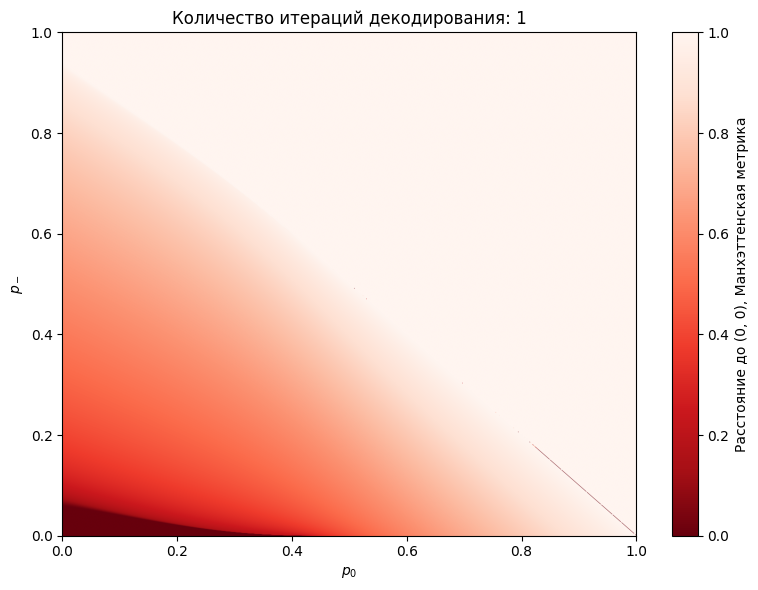

In [ ]:
p0_lim = np.float64(0)
p_minus_lim = np.float64(0)

p0_vals = np.linspace(0, 1, 1000, dtype=np.float64)
p_minus_vals = np.linspace(0, 1, 1000, dtype=np.float64)
p_heat = []

p_heat = []
for p0, p_minus in tqdm(product(p0_vals, p_minus_vals), total=len(p0_vals)*len(p_minus_vals), desc="Grid search"):
    if p0 + p_minus <= 1:
        p0_example, p_minus_example, p_plus_example = density_evolution_bec(
            epsilon=p0,
            delta=p_minus,
            l=3,
            k=6,
            num_iters=20
        )
    else:
        p0_example, p_minus_example = [0.5], [0.5]
    p_heat.append(min(p0_example[-1] + p_minus_example[-1], 1))

# Преобразуем в матрицу для тепловой карты
p_heat = np.array(p_heat).reshape(len(p0_vals), len(p_minus_vals))

# Построение графика
plt.figure(figsize=(8, 6))
plt.imshow(p_heat.T, origin='lower', extent=(p0_vals[0], p0_vals[-1], p_minus_vals[0], p_minus_vals[-1]),
           aspect='auto', cmap='Reds_r')
plt.colorbar(label='Расстояние до (0, 0), Манхэттенская метрика')
plt.title('Количество итераций декодирования: 1')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.tight_layout()

Progress: [##################################################]100%(1, 2)

Task done!
Progress: [##################################################(2, 4)
]100%
Task done!
Progress: [##################################################]100%
Task done!
(3, 6)
Progress: [###########(4, 8)#########################        ] 84%
Progress: [##################################################]100%
Task done!
Progress: [##################################################]100%
Task done!
(5, 10)
Progress: [##################################################]100%                 ] 10%
Task done!
(6, 12)


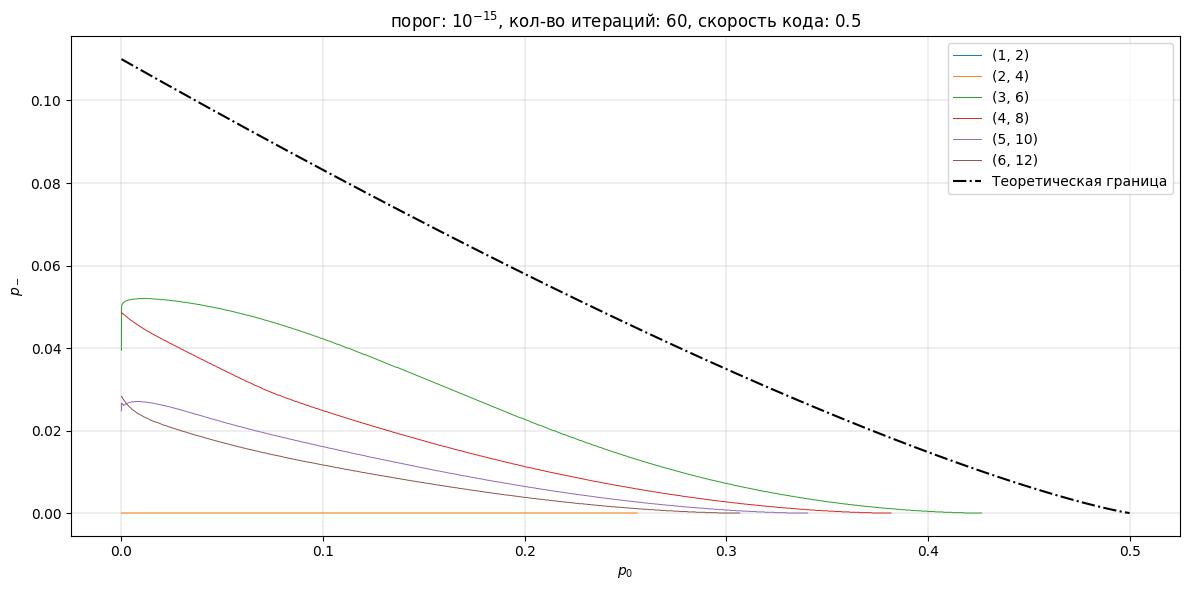

In [14]:
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(1e-3, 0.45, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)

threshold = 1e-15

not_r = 2


plt.figure(figsize=(12, 6))
for l in range(1, 7):
    num_iters = 60
    results = np.full(len(p0_vals), -1, dtype=np.float64)

    lib.density_evolution_grid(
        p0_vals, len(p0_vals),
        p_minus_vals, len(p_minus_vals),
        l, l * not_r, num_iters,
        threshold,
        results
    )
    print(f'({l}, {l*not_r})')
    mask = results > -1
    points = np.array([p0_vals[np.argwhere(mask)].ravel(), p_minus_vals[results[mask].astype(int)].ravel()])
    plt.plot(points[0, :], points[1, :], label=f'({l}, {l*not_r})', linewidth=0.7)

plt.plot(*decoding_limit(), label="Теоретическая граница", color='black', linestyle='-.')
plt.title(f'порог: $10^{{{int(np.log10(threshold))}}}$, кол-во итераций: 60, скорость кода: 0.5')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend(loc='upper right')
plt.tight_layout()

Progress: [###########################################(3, 6) ] 99%
#######]100%
Task done!
Progress: [##################################################]100%
Task done!
(5, 10)
Progress: [##################################################]100%####   ] 95%
Task done!
(7, 14)
Progress: [##################################################]100%###################################              ] 73%
Task done!
(9, 18)


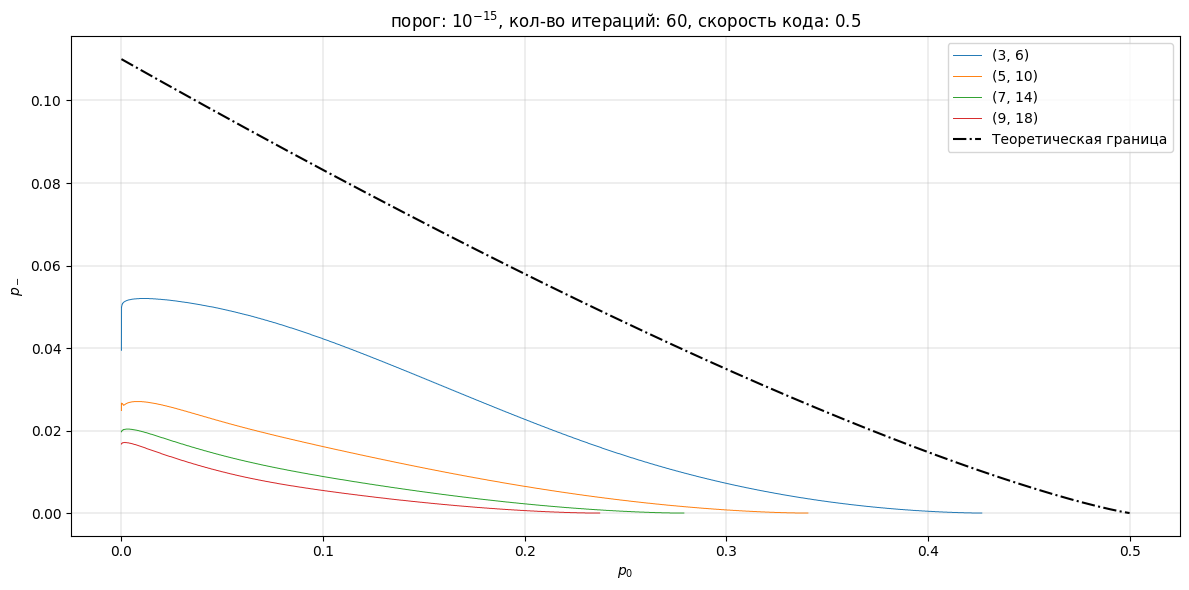

In [15]:
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 2000),
    np.linspace(1e-3, 0.55, 2000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 2000, dtype=np.float64)

threshold = 1e-15

not_r = 2

plt.figure(figsize=(12, 6))
for l in range(3, 10, 2):
    num_iters = 60
    results = np.full(len(p0_vals), -1, dtype=np.float64)

    lib.density_evolution_grid(
        p0_vals, len(p0_vals),
        p_minus_vals, len(p_minus_vals),
        l, l * not_r, num_iters,
        threshold,
        results
    )
    print(f'({l}, {l*not_r})')
    mask = results > -1
    points = np.array([p0_vals[np.argwhere(mask)].ravel(), p_minus_vals[results[mask].astype(int)].ravel()])
    plt.plot(points[0, :], points[1, :], label=f'({l}, {l*not_r})', linewidth=0.7)

plt.plot(*decoding_limit(), label="Теоретическая граница", color='black', linestyle='-.')
plt.title(f'порог: $10^{{{int(np.log10(threshold))}}}$, кол-во итераций: 60, скорость кода: 0.5')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("de_bec_thr_10^-15_3-9_step2.png")

Progress: [##################################################(3, 6)
]100%
Task done!
Progress: [##################################################]100%
Task done!
(3, 6)
Progress: [################################################(3, 6)%
##]100%
Task done!
Progress: [##################################################]100%
Task done!
(3, 6)
Progress: [############################################(3, 6)] 99%
######]100%
Task done!


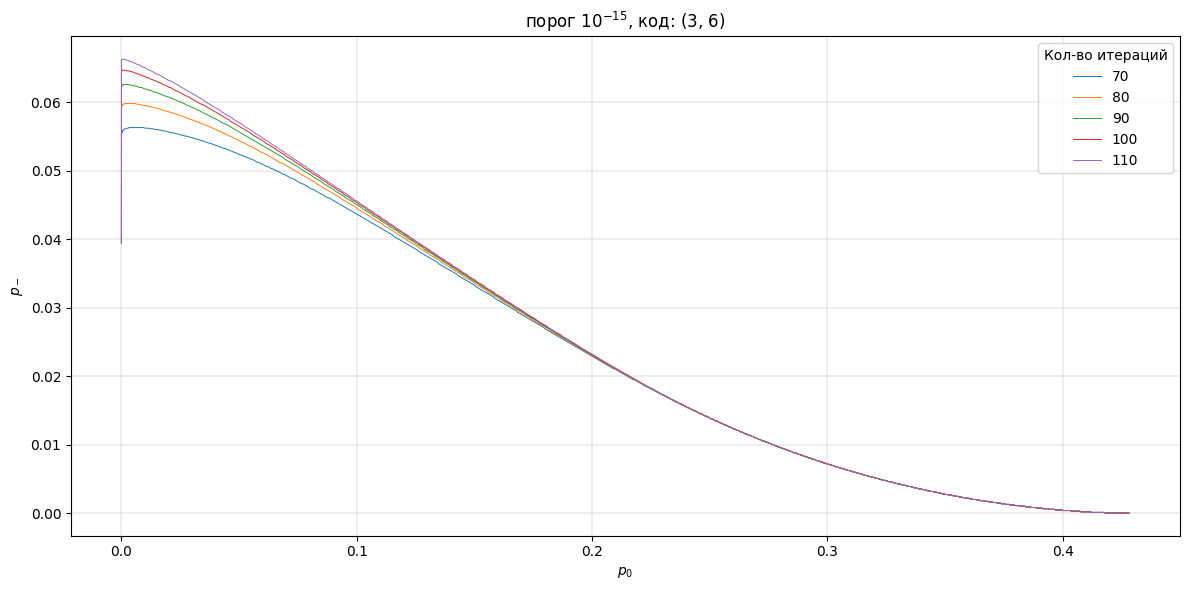

In [16]:
# Сетка значений
p0_vals = np.concatenate([
    np.logspace(-20, -3, 1000),
    np.linspace(1e-3, 0.45, 1000, dtype=np.float64)
])
p_minus_vals = np.linspace(0, 0.09, 1000, dtype=np.float64)

threshold = 1e-15

not_r = 2
l = 3

plt.figure(figsize=(12, 6))
for num_iters in range(70, 111, 10):
    results = np.full(len(p0_vals), -1, dtype=np.float64)

    lib.density_evolution_grid(
        p0_vals, len(p0_vals),
        p_minus_vals, len(p_minus_vals),
        l, l * not_r, num_iters,
        threshold,
        results
    )
    print(f'({l}, {l*not_r})')
    mask = results > -1
    points = np.array([p0_vals[np.argwhere(mask)].ravel(), p_minus_vals[results[mask].astype(int)].ravel()])
    plt.plot(points[0, :], points[1, :], label=f'{num_iters}', linewidth=0.7)

plt.title(f'порог $10^{{{int(np.log10(threshold))}}}$, код: (3, 6)')
plt.xlabel('$p_0$')
plt.ylabel('$p_-$')
plt.grid(linewidth=0.3)
plt.legend(title="Кол-во итераций")
plt.tight_layout()
plt.savefig("de_bec_thr_10^-15_3-9_step2.png")